# Analysis of the results

## 1. Data Loading

In [41]:
import pandas as pd
import pyarrow.parquet as pq

# PARQUET_FILE = "data/solver_results.parquet"
PARQUET_FILE = "data/solver_results_forcing_base_10.parquet"

# Just metadata - very fast, no data load
pf = pq.ParquetFile(PARQUET_FILE)
print(pf.schema)              # schema with types
print(pf.metadata)            # row count, row groups, size
print(pf.metadata.num_rows)

# Read only specific columns
# df = pq.read_table(PARQUET_FILE, columns=['col1', 'col2']).to_pandas()

required group field_id=-1 schema {
  optional binary field_id=-1 id (String);
  optional binary field_id=-1 prompt (String);
  optional binary field_id=-1 answer (String);
  optional binary field_id=-1 solver_answer (String);
  optional boolean field_id=-1 solver_correct;
  optional binary field_id=-1 solver_strategy (String);
  optional binary field_id=-1 category (String);
  optional binary field_id=-1 ops_mapping (String);
  optional binary field_id=-1 digits_mapping (String);
  optional binary field_id=-1 solver_tier (String);
  optional double field_id=-1 solver_radix;
  optional binary field_id=-1 ops_candidates (String);
  optional binary field_id=-1 equations (String);
  optional int64 field_id=-1 solution_count;
  optional binary field_id=-1 search_reached (String);
}

  created_by: parquet-cpp-arrow version 24.0.0
  num_columns: 15
  num_rows: 1472
  num_row_groups: 1
  format_version: 2.6
  serialized_size: 10082
1472


In [42]:
df = pq.read_table(PARQUET_FILE).to_pandas()
df

,id,prompt,answer,solver_answer,solver_correct,solver_strategy,category,ops_mapping,digits_mapping,solver_tier,solver_radix,ops_candidates,equations,solution_count,search_reached
0,00457d26,"In Alice's Wonderland, a secret set of transfo...",@&,@&,True,standard,arithmetic,"{""*"": ""mul_p1"", ""-"": ""absdiff""}","{""`"": 5, ""!"": 6, ""["": 4, ""{"": 9, ""'"": 2, ""\"""":...",full,10.0,"{""*"": [""mul_p1""], ""-"": [""absdiff"", ""rsub_signe...","[{""type"": ""example"", ""lhs"": {""l0"": ""`"", ""l1"": ...",1,little_endian
1,00c032a8,"In Alice's Wonderland, a secret set of transfo...",\^?,\^?,True,little_endian,arithmetic,"{""!"": ""mul"", ""]"": ""add"", ""<"": ""absdiff""}","{""}"": 5, ""`"": 4, ""?"": 2, ""("": 7, "")"": 1, ""#"": ...",full,10.0,"{""!"": [""mul""], ""]"": [""add""], ""<"": [""absdiff"", ...","[{""type"": ""example"", ""lhs"": {""l0"": ""}"", ""l1"": ...",1,little_endian
2,012cab1f,"In Alice's Wonderland, a secret set of transfo...",|@{,|@{,True,little_endian,arithmetic,"{""'"": ""add"", "">"": ""absdiff"", ""]"": ""mul""}","{""`"": 7, ""("": 9, ""&"": 6, "":"": 8, ""%"": 2, ""@"": ...",full,10.0,"{""'"": [""add""], "">"": [""absdiff"", ""rsub_signed""]...","[{""type"": ""example"", ""lhs"": {""l0"": ""`"", ""l1"": ...",1,little_endian
3,0133bcec,"In Alice's Wonderland, a secret set of transfo...",\([#,\([#,True,pure_concat,concatenation,NaN,NaN,NaN,NaN,NaN,"[{""type"": ""example"", ""lhs"": {""l0"": ""%"", ""l1"": ...",1,NaN
4,017a871e,"In Alice's Wonderland, a secret set of transfo...",\:,\:,True,little_endian,arithmetic,"{""-"": ""absdiff_m2"", ""+"": ""add_p2"", ""*"": ""a2_pl...","{""#"": 2, ""]"": 6, ""\\"": 3, ""\"""": 7, ""!"": 8, ""^""...",full,10.0,"{""-"": [""absdiff_m2""], ""+"": [""add_p2""], ""*"": [""...","[{""type"": ""example"", ""lhs"": {""l0"": ""#"", ""l1"": ...",1,little_endian
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1467,fdbdf50c,"In Alice's Wonderland, a secret set of transfo...","-\""","-\""",True,little_endian,arithmetic,"{""-"": ""sub_signed"", ""}"": ""add"", ""("": ""mul""}","{""%"": 0, ""?"": 8, "")"": 9, ""\\"": 3, ""^"": 1, ""]"":...",full,10.0,"{""-"": [""sub_signed""], ""}"": [""add""], ""("": [""mul""]}","[{""type"": ""example"", ""lhs"": {""l0"": ""%"", ""l1"": ...",1,little_endian
1468,fe6da79d,"In Alice's Wonderland, a secret set of transfo...",:&]!,:&]!,True,standard,arithmetic,"{""-"": ""neg_absdiff"", ""*"": ""mul"", ""+"": ""concat_...","{""\\"": 9, ""&"": 5, "":"": 1, ""$"": 3, ""}"": 8, ""#"":...",full,10.0,"{""-"": [""neg_absdiff""], ""*"": [""mul""], ""+"": [""co...","[{""type"": ""example"", ""lhs"": {""l0"": ""\\"", ""l1"":...",1,little_endian
1469,ff0e37ae,"In Alice's Wonderland, a secret set of transfo...","%'""`","%'""`",True,pure_concat,concatenation,NaN,NaN,NaN,NaN,NaN,"[{""type"": ""example"", ""lhs"": {""l0"": ""?"", ""l1"": ...",1,NaN
1470,ff121f08,"In Alice's Wonderland, a secret set of transfo...",#<,#<,True,standard,arithmetic,"{""+"": ""sub_signed"", ""("": ""mul"", ""\\"": ""add_p1""}","{""%"": 4, ""`"": 8, ""^"": 7, ""<"": 2, ""#"": 1, ""!"": ...",full,10.0,"{""+"": [""sub_signed""], ""("": [""mul"", ""lcm""], ""\\...","[{""type"": ""example"", ""lhs"": {""l0"": ""%"", ""l1"": ...",1,little_endian


In [36]:
df[df['solution_count'] == 5]

,id,prompt,answer,solver_answer,solver_correct,solver_strategy,category,ops_mapping,digits_mapping,solver_tier,solver_radix,ops_candidates,equations,solution_count,search_reached,num_unique_symbols,op_in_rhs_last_eqs
15,03a3437f,"In Alice's Wonderland, a secret set of transfo...",-!,-!,True,standard,arithmetic,"{""-"": ""sub_signed"", ""+"": ""concat_fwd""}","{""/"": 3, "">"": 7, ""|"": 1, ""'"": 2, "":"": 4, ""!"": ...",full,10.0,"{""-"": [""sub_signed""], ""+"": [""concat_fwd""]}","[{'type': 'example', 'lhs': {'l0': '/', 'l1': ...",5,little_endian,8,[]
16,03a3437f,"In Alice's Wonderland, a secret set of transfo...",-!,-!,True,standard,arithmetic,"{""-"": ""sub_signed"", ""+"": ""concat_fwd""}","{""/"": 5, "">"": 3, ""|"": 0, ""'"": 4, "":"": 8, ""!"": ...",full,10.0,"{""-"": [""sub_signed""], ""+"": [""concat_fwd""]}","[{'type': 'example', 'lhs': {'l0': '/', 'l1': ...",5,little_endian,8,[]
17,03a3437f,"In Alice's Wonderland, a secret set of transfo...",-!,-!,True,standard,arithmetic,"{""-"": ""sub_signed"", ""+"": ""concat_fwd""}","{""/"": 8, "">"": 1, ""|"": 0, ""'"": 7, "":"": 3, ""!"": ...",full,10.0,"{""-"": [""sub_signed""], ""+"": [""concat_fwd""]}","[{'type': 'example', 'lhs': {'l0': '/', 'l1': ...",5,little_endian,8,[]
18,03a3437f,"In Alice's Wonderland, a secret set of transfo...",-!,-!,True,little_endian,arithmetic,"{""-"": ""rsub_signed"", ""+"": ""concat_fwd""}","{""/"": 9, "">"": 5, ""|"": 0, ""'"": 1, "":"": 3, ""!"": ...",full,10.0,"{""-"": [""rsub_signed""], ""+"": [""concat_fwd""]}","[{'type': 'example', 'lhs': {'l0': '/', 'l1': ...",5,little_endian,8,[]
19,03a3437f,"In Alice's Wonderland, a secret set of transfo...",-!,-!,True,little_endian,arithmetic,"{""-"": ""rsub_signed"", ""+"": ""concat_fwd""}","{""/"": 7, "">"": 1, ""|"": 0, ""'"": 3, "":"": 5, ""!"": ...",full,10.0,"{""-"": [""rsub_signed""], ""+"": [""concat_fwd""]}","[{'type': 'example', 'lhs': {'l0': '/', 'l1': ...",5,little_endian,8,[]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1199,fc7e4f9b,"In Alice's Wonderland, a secret set of transfo...",?<,?<,True,standard,arithmetic,"{""-"": ""absdiff"", ""+"": ""add_p2"", ""*"": ""concat_f...","{""^"": 7, ""&"": 4, "")"": 8, ""$"": 5, ""<"": 1, ""{"": ...",full,10.0,"{""-"": [""absdiff"", ""rsub_signed"", ""rmod""], ""+"":...","[{'type': 'example', 'lhs': {'l0': '^', 'l1': ...",5,little_endian,10,[]
1200,fc7e4f9b,"In Alice's Wonderland, a secret set of transfo...",?<,?<,True,standard,arithmetic,"{""-"": ""absdiff"", ""+"": ""add"", ""*"": ""concat_fwd""}","{""^"": 7, ""&"": 4, "")"": 8, ""$"": 5, ""<"": 1, ""{"": ...",full,10.0,"{""-"": [""absdiff"", ""rsub_signed"", ""rmod""], ""+"":...","[{'type': 'example', 'lhs': {'l0': '^', 'l1': ...",5,little_endian,10,[]
1201,fc7e4f9b,"In Alice's Wonderland, a secret set of transfo...",?<,?<,True,standard,arithmetic,"{""-"": ""absdiff"", ""+"": ""add_p2"", ""*"": ""concat_f...","{""^"": 7, ""&"": 4, "")"": 8, ""$"": 5, ""<"": 1, ""{"": ...",full,10.0,"{""-"": [""absdiff"", ""rsub_signed"", ""rmod""], ""+"":...","[{'type': 'example', 'lhs': {'l0': '^', 'l1': ...",5,little_endian,10,[]
1202,fc7e4f9b,"In Alice's Wonderland, a secret set of transfo...",?<,?<,True,standard,arithmetic,"{""-"": ""absdiff"", ""+"": ""add"", ""*"": ""concat_fwd""}","{""^"": 7, ""&"": 4, "")"": 8, ""$"": 5, ""<"": 1, ""{"": ...",full,10.0,"{""-"": [""absdiff"", ""rsub_signed"", ""rmod""], ""+"":...","[{'type': 'example', 'lhs': {'l0': '^', 'l1': ...",5,little_endian,10,[]


In [43]:
df['solution_count'].unique()

array([ 1,  0,  5, 10,  2,  4,  3,  6,  9,  8])

In [6]:
df['solver_tier'].unique()

<ArrowStringArray>
['full', nan]
Length: 2, dtype: str

In [7]:
df['solver_strategy'].value_counts()

solver_strategy
standard         723
little_endian    394
pure_concat       75
Name: count, dtype: int64

In [8]:
df['category'].value_counts(dropna=False)

category
arithmetic       1117
concatenation      75
NaN                19
Name: count, dtype: int64

## 2. Sample Inspection

In [9]:
test = df[df['id'] == '1cce5949']#
test

,id,prompt,answer,solver_answer,solver_correct,solver_strategy,category,ops_mapping,digits_mapping,solver_tier,solver_radix,ops_candidates,equations,solution_count,search_reached
144,1cce5949,"In Alice's Wonderland, a secret set of transfo...",[?},[?},True,little_endian,arithmetic,"{""}"": ""rsub_signed"", ""/"": ""mul"", ""-"": ""add""}","{""$"": 7, ""?"": 5, ""%"": 3, ""`"": 2, ""]"": 1, ""\"""":...",full,10.0,"{""}"": [""rsub_signed"", ""neg_absdiff""], ""/"": [""m...","[{""type"": ""example"", ""lhs"": {""l0"": ""$"", ""l1"": ...",1,little_endian


In [10]:
print(test['equations'].iloc[0])    

[{"type": "example", "lhs": {"l0": "$", "l1": "?", "op": "/", "r0": "%", "r1": "`"}, "rhs": {"op": null, "sign_pos": null, "actual_rhs": ["]", "]", "%", "]"]}}, {"type": "example", "lhs": {"l0": "%", "l1": "$", "op": "/", "r0": "\"", "r1": "?"}, "rhs": {"op": null, "sign_pos": null, "actual_rhs": ["$", "[", "%", ">"]}}, {"type": "example", "lhs": {"l0": "[", "l1": "?", "op": "-", "r0": "\\", "r1": "\""}, "rhs": {"op": null, "sign_pos": null, "actual_rhs": ["\\", ">", "]"]}}, {"type": "example", "lhs": {"l0": "`", "l1": "]", "op": "/", "r0": "\\", "r1": ">"}, "rhs": {"op": null, "sign_pos": null, "actual_rhs": ["`", "?", "?"]}}, {"type": "to_predict", "lhs": {"l0": "`", "l1": "\\", "op": "}", "r0": "`", "r1": "]"}, "rhs": {"op": "}", "sign_pos": "postfix", "actual_rhs": ["[", "?"]}}]


In [11]:
prompt= df[df['id'] == '1d15b7e6']['prompt']
print(prompt.iloc[0])

In Alice's Wonderland, a secret set of transformation rules is applied to equations. Below are a few examples:
^$)[^ = [^^{
^^?[" = {^(
![@({ = $$@
[}@{( = $^@
Now, determine the result for: |[)$[


In [12]:
df.iloc[0]['ops_candidates']

'{"*": ["mul_p1"], "-": ["absdiff", "rsub_signed"]}'

## 3. Dataset Overview

In [13]:
df['solver_strategy'].unique()

<ArrowStringArray>
['standard', 'little_endian', 'pure_concat', nan]
Length: 4, dtype: str

In [14]:
df['solver_radix'].unique()

array([10., nan])

## 4. Operation Frequency Analysis
Counts how often each operation is mapped (number of puzzles) and how often it appears across all equations (occurrences). Splits by solver mode (standard vs. little-endian) and computes sampling probabilities with temperature scaling.

In [15]:
import json
from collections import Counter
from src.solver_eq_symbolic import OP_NAME_TO_IDX

ALL_OPS = list(OP_NAME_TO_IDX.keys())  # canonical ops, index order

def count_ops(rows):
    mapping_counter = Counter()
    occurrence_counter = Counter()
    for _, row in rows.iterrows():
        ops_json = row['ops_mapping']
        if pd.isna(ops_json) if isinstance(ops_json, float) else ops_json is None:
            continue
        ops = json.loads(ops_json)  # {op_char: op_name}

        # Count per-equation occurrences from the stored equations JSON
        eq_counts = Counter()
        equations_json = row['equations']
        if equations_json and not (isinstance(equations_json, float) and pd.isna(equations_json)):
            try:
                for eq in json.loads(equations_json):
                    eq_counts[eq['lhs']['op']] += 1
            except Exception:
                pass

        for op_char, op_name in ops.items():
            mapping_counter[op_name] += 1
            occurrence_counter[op_name] += eq_counts.get(op_char, 0)

    return mapping_counter, occurrence_counter

# standard = big-endian mode; little_endian = reversed-digit mode
df_arith = df[df['solver_strategy'].isin(['standard', 'little_endian'])]
df_std   = df_arith[df_arith['solver_strategy'] == 'standard']
df_le    = df_arith[df_arith['solver_strategy'] == 'little_endian']

std_map,   std_occ   = count_ops(df_std)
le_map,    le_occ    = count_ops(df_le)
total_map, total_occ = count_ops(df_arith)

freq = pd.DataFrame({
    'operation':        ALL_OPS,
    'std_mapping':      [std_map.get(op, 0)   for op in ALL_OPS],
    'std_occurrence':   [std_occ.get(op, 0)   for op in ALL_OPS],
    'le_mapping':       [le_map.get(op, 0)    for op in ALL_OPS],
    'le_occurrence':    [le_occ.get(op, 0)    for op in ALL_OPS],
    'total_mapping':    [total_map.get(op, 0) for op in ALL_OPS],
    'total_occurrence': [total_occ.get(op, 0) for op in ALL_OPS],
}).sort_values('total_mapping', ascending=False).reset_index(drop=True)

print(f"Non-concat puzzles: {len(df_arith)}  (standard={len(df_std)}, little_endian={len(df_le)})")
print(f"Ops with zero mapping count: {(freq['total_mapping'] == 0).sum()} / {len(ALL_OPS)}")

with pd.option_context('display.max_rows', None):
    display(freq)

Non-concat puzzles: 1117  (standard=723, little_endian=394)
Ops with zero mapping count: 0 / 22


,operation,std_mapping,std_occurrence,le_mapping,le_occurrence,total_mapping,total_occurrence
0,mul,222,430,230,451,452,881
1,add,219,444,220,418,439,862
2,sub_signed,224,451,147,335,371,786
3,concat_fwd,330,603,19,28,349,631
4,absdiff,189,344,113,191,302,535
5,add_m1,96,183,28,51,124,234
6,add_p1,79,147,37,67,116,214
7,mul_m1,92,164,18,37,110,201
8,rsub_signed,67,105,40,86,107,191
9,mul_p1,79,140,23,44,102,184


In [16]:
freq.sum()

operation           muladdsub_signedconcat_fwdabsdiffadd_m1add_p1m...
std_mapping                                                      1909
std_occurrence                                                   3536
le_mapping                                                       1007
le_occurrence                                                    1950
total_mapping                                                    2916
total_occurrence                                                 5486
dtype: object

In [17]:
# Probability the issue is solved with an standard method
prob_std = freq['std_mapping'].sum() / freq['total_mapping'].sum() 
print(f"Probability of standard method solving the issue: {prob_std:.4f}")

# Probability the issue is solved with a little-endian method
prob_le = freq['le_mapping'].sum() / freq['total_mapping'].sum()
print(f"Probability of little-endian method solving the issue: {prob_le:.4f}")

Probability of standard method solving the issue: 0.6547
Probability of little-endian method solving the issue: 0.3453


In [18]:
#
filter_df = freq[(freq['total_mapping'] > 0) & (freq['total_occurrence'] > 0)]
filter_df = filter_df[['operation', 'total_mapping']]
filter_df

,operation,total_mapping
0,mul,452
1,add,439
2,sub_signed,371
3,concat_fwd,349
4,absdiff,302
5,add_m1,124
6,add_p1,116
7,mul_m1,110
8,rsub_signed,107
9,mul_p1,102


In [19]:
import numpy as np

## Calculate the probabilities accross the tototal mapping count and the total occurrence count. Use a temperature value
TEMPERATURE = 1.0
filter_df['mapping_prob_temp'] = filter_df['total_mapping']**(1/TEMPERATURE)
# filter_df['occurrence_prob_temp'] = filter_df['total_occurrence']**(1/TEMPERATURE)
filter_df['mapping_prob_temp'] /= filter_df['mapping_prob_temp'].sum()
# filter_df['occurrence_prob_temp'] /= filter_df['occurrence_prob_temp'].sum()

# TEMPERATURE = 0.7
# filter_df['mapping_prob_temp_exp'] = np.exp(filter_df['total_mapping'] / TEMPERATURE) / np.exp(filter_df['total_mapping'] / TEMPERATURE).sum()

filter_df

,operation,total_mapping,mapping_prob_temp
0,mul,452,0.155007
1,add,439,0.150549
2,sub_signed,371,0.127229
3,concat_fwd,349,0.119684
4,absdiff,302,0.103567
5,add_m1,124,0.042524
6,add_p1,116,0.039781
7,mul_m1,110,0.037723
8,rsub_signed,107,0.036694
9,mul_p1,102,0.034979


## 5. Radix / Base Distribution
Checks which numeric bases (radix) the solver uses across all puzzles.

In [20]:
# checking the radix frequency
df['solver_radix'].value_counts()

solver_radix
10.0    1117
Name: count, dtype: int64

## 6. Equation & Symbol Extraction
Reconstructs the full equation set per puzzle (examples + query with answer) and counts unique symbols per sample.

In [21]:
import json
from src.parsing import content_symbols

df['equations'] = df['equations'].apply(
    lambda v: json.loads(v) if v and not (isinstance(v, float) and pd.isna(v)) else []
)
df['num_unique_symbols'] = df['equations'].apply(
    lambda eqs: len(content_symbols(eqs)) if eqs else 0
)

print(f"Sample equations for row 0:\n{df['equations'][0]}\n")
print(f"Unique symbol counts — min: {df['num_unique_symbols'].min()}, max: {df['num_unique_symbols'].max()}, mean: {df['num_unique_symbols'].mean():.2f}")
df[['id', 'equations', 'num_unique_symbols']].head(10)

Sample equations for row 0:
[{'type': 'example', 'lhs': {'l0': '`', 'l1': '!', 'op': '*', 'r0': '[', 'r1': '{'}, 'rhs': {'op': None, 'sign_pos': None, 'actual_rhs': ["'", '"', '[', '`']}}, {'type': 'example', 'lhs': {'l0': '\\', 'l1': "'", 'op': '*', 'r0': "'", 'r1': '>'}, 'rhs': {'op': None, 'sign_pos': None, 'actual_rhs': ['!', '[', '@']}}, {'type': 'example', 'lhs': {'l0': '\\', 'l1': "'", 'op': '-', 'r0': '!', 'r1': '`'}, 'rhs': {'op': None, 'sign_pos': None, 'actual_rhs': ['\\', '\\']}}, {'type': 'example', 'lhs': {'l0': '`', 'l1': '!', 'op': '*', 'r0': '\\', 'r1': '&'}, 'rhs': {'op': None, 'sign_pos': None, 'actual_rhs': ["'", '@', "'", '{']}}, {'type': 'to_predict', 'lhs': {'l0': '[', 'l1': '[', 'op': '-', 'r0': '!', 'r1': "'"}, 'rhs': {'op': None, 'sign_pos': None, 'actual_rhs': ['@', '&']}}]

Unique symbol counts — min: 6, max: 10, mean: 9.43


,id,equations,num_unique_symbols
0,00457d26,"[{'type': 'example', 'lhs': {'l0': '`', 'l1': ...",10
1,00c032a8,"[{'type': 'example', 'lhs': {'l0': '}', 'l1': ...",10
2,012cab1f,"[{'type': 'example', 'lhs': {'l0': '`', 'l1': ...",10
3,0133bcec,"[{'type': 'example', 'lhs': {'l0': '%', 'l1': ...",9
4,017a871e,"[{'type': 'example', 'lhs': {'l0': '#', 'l1': ...",8
5,01b2aa67,"[{'type': 'example', 'lhs': {'l0': ':', 'l1': ...",9
6,01ef1e3e,"[{'type': 'example', 'lhs': {'l0': ''', 'l1': ...",10
7,022c4d73,"[{'type': 'example', 'lhs': {'l0': '/', 'l1': ...",9
8,02664ad5,"[{'type': 'example', 'lhs': {'l0': '`', 'l1': ...",10
9,02902eb3,"[{'type': 'example', 'lhs': {'l0': '!', 'l1': ...",9


## 7. Symbol Distribution Analysis
Analyzes how operator symbols are distributed across puzzles: frequency per symbol, per LHS position, and cross-position correlation.

<Axes: >

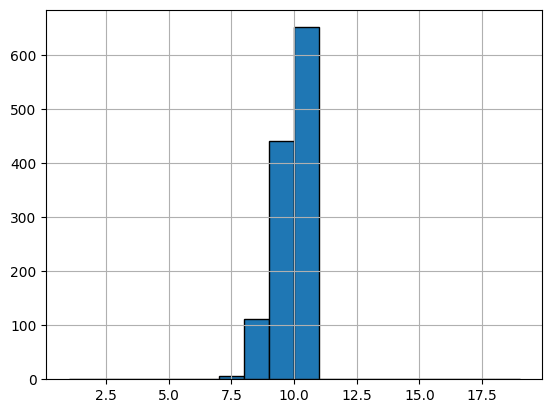

In [22]:
df['num_unique_symbols'].hist(bins=range(1, 20), edgecolor='black')

In [23]:

# Operator symbols: extract position-2 (middle of 5-char LHS) from every equation in every prompt
from collections import Counter

op_sym_counts = Counter()
total_equations = 0

for _, row in df.iterrows():
    for line in row['prompt'].split('\n'):
        if ' = ' not in line or line.startswith('Now'):
            continue
        lhs = line.split(' = ', 1)[0]
        # All LHS are 5 chars; operator is always at index 2
        if len(lhs) == 5:
            op_sym_counts[lhs[2]] += 1
            total_equations += 1

sym_df = pd.DataFrame(
    [(sym, cnt, round(cnt / total_equations * 100, 2))
     for sym, cnt in op_sym_counts.most_common()],
    columns=['operator_symbol', 'equation_count', 'pct_of_equations']
)

print(f"Total equations parsed: {total_equations}")
print(f"Unique operator symbols: {len(op_sym_counts)}\n")
with pd.option_context('display.max_rows', None):
    display(sym_df)


Total equations parsed: 4756
Unique operator symbols: 26



,operator_symbol,equation_count,pct_of_equations
0,*,1167,24.54
1,+,1156,24.31
2,-,1092,22.96
3,',89,1.87
4,),80,1.68
5,{,77,1.62
6,\,75,1.58
7,|,66,1.39
8,:,62,1.30
9,#,62,1.30


In [24]:

# Compare symbol frequency distribution across all 5 LHS positions
import numpy as np

pos_counts = [Counter() for _ in range(5)]
total = 0

for _, row in df.iterrows():
    for line in row['prompt'].split('\n'):
        if ' = ' not in line or line.startswith('Now'):
            continue
        lhs = line.split(' = ', 1)[0]
        if len(lhs) == 5:
            for i, ch in enumerate(lhs):
                pos_counts[i][ch] += 1
            total += 1

all_syms = sorted(set().union(*pos_counts))

rows = []
for i, c in enumerate(pos_counts):
    counts = [c.get(s, 0) for s in all_syms]
    top3 = ', '.join(f'{s}={n}' for s, n in c.most_common(3))
    rows.append({
        'position':    f'pos{i} (operator)' if i == 2 else f'pos{i}',
        'unique_syms': len(c),
        'min':         min(counts),
        'max':         max(counts),
        'std':         round(np.std(counts), 1),
        'top3':        top3,
    })

display(pd.DataFrame(rows))

# Pearson correlation between position frequency vectors
vecs = [np.array([c.get(s, 0) for s in all_syms], dtype=float) for c in pos_counts]
corr = np.array([[np.corrcoef(vecs[i], vecs[j])[0, 1] for j in range(5)] for i in range(5)])
corr_df = pd.DataFrame(corr,
                       index=[f'pos{i}' for i in range(5)],
                       columns=[f'pos{i}' for i in range(5)]).round(3)
print("\nPearson correlation between position frequency vectors:")
display(corr_df)


,position,unique_syms,min,max,std,top3
0,pos0,23,0,247,69.3,"/=247, $=246, `=236"
1,pos1,23,0,241,68.8,"#=241, |=234, (=227"
2,pos2 (operator),26,44,1167,345.4,"*=1167, +=1156, -=1092"
3,pos3,23,0,274,70.8,"|=274, #=242, [=232"
4,pos4,23,0,247,67.8,"}=247, !=237, |=227"



Pearson correlation between position frequency vectors:


,pos0,pos1,pos2,pos3,pos4
pos0,1.000,0.933,-0.956,0.891,0.920
pos1,0.933,1.000,-0.957,0.953,0.939
pos2,-0.956,-0.957,1.000,-0.931,-0.973
pos3,0.891,0.953,-0.931,1.000,0.917
pos4,0.920,0.939,-0.973,0.917,1.000


## 8. Operation-Symbol Mapping
Shows which operations get assigned to the three most common operator symbols (`*`, `+`, `-`) across all puzzles.

In [25]:

# Operations mapped to *, -, + across all samples
from collections import defaultdict
target_syms = ['*', '+', '-']

# Extend the target symb with the other symbols
for sym in sym_df['operator_symbol']:
    if sym not in target_syms:
        target_syms.append(sym)

op_map = defaultdict(Counter)  # sym -> {op_name: count}

for _, row in df.iterrows():
    if pd.isna(row['ops_mapping']):
        continue
    ops = json.loads(row['ops_mapping'])
    for sym, op_name in ops.items():
        if sym in target_syms:
            op_map[sym][op_name] += 1

# Build a wide table: rows = operation names, columns = symbols
all_ops = sorted(set(op for c in op_map.values() for op in c))
table = pd.DataFrame(
    {sym: [op_map[sym].get(op, 0) for op in all_ops] for sym in target_syms},
    index=all_ops
)
table.index.name = 'operation'
table['total'] = table.sum(axis=1)
table = table.sort_values('total', ascending=False)

print("Rows = operation name, Columns = operator symbol, Values = number of puzzles mapped")
display(table)


Rows = operation name, Columns = operator symbol, Values = number of puzzles mapped


,*,+,-,',),{,\,|,:,#,...,(,%,?,@,],[,>,$,/,total
operation,,,,,,,,,,,,,,,,,,,,,
mul,242,15,17,10,10,10,10,10,13,7,...,9,5,10,4,5,6,7,4,11,452
add,16,214,12,11,11,9,9,11,4,7,...,4,14,5,8,6,8,8,10,4,439
sub_signed,12,8,233,6,8,1,4,6,9,2,...,6,10,10,0,4,4,1,1,5,371
concat_fwd,150,121,0,6,0,9,10,5,0,0,...,2,0,1,7,5,6,1,5,2,349
absdiff,10,18,197,6,3,7,1,1,4,11,...,3,4,5,4,3,1,2,2,1,302
add_m1,6,97,4,1,1,0,0,0,0,0,...,0,0,0,2,0,2,0,1,0,124
add_p1,3,91,3,0,3,0,3,0,0,0,...,0,1,0,1,0,0,0,2,0,116
mul_m1,86,7,1,2,1,0,0,0,1,0,...,2,0,1,0,0,0,1,4,1,110
rsub_signed,1,3,71,2,7,1,2,0,2,0,...,1,0,1,1,3,0,2,0,2,107


In [26]:
# Top 3 operations per symbol
top3_rows = []
for sym in target_syms:
    for op, cnt in op_map[sym].most_common(3):
        top3_rows.append({'symbol': sym, 'rank': op_map[sym].most_common().index((op, cnt)) + 1, 'operation': op, 'count': cnt})

top3_df = pd.DataFrame(top3_rows)
top3_pivot = top3_df.pivot_table(index=['rank', 'operation'], columns='symbol', values='count', fill_value=0)

# Simpler wide format: one row per (symbol, rank)
top3_wide = (
    top3_df
    .assign(label=top3_df['operation'] + ' (' + top3_df['count'].astype(str) + ')')
    .pivot(index='rank', columns='symbol', values='label')
    .fillna('')
)
top3_wide.columns.name = None
top3_wide.index.name = 'rank'

print("Top 3 operations per operator symbol (count in parentheses)")
display(top3_wide[target_syms])  # keep symbol column order


Top 3 operations per operator symbol (count in parentheses)


,*,+,-,',),{,\,|,:,#,...,!,(,%,?,@,],[,>,$,/
rank,,,,,,,,,,,,,,,,,,,,,
1,mul (242),add (214),sub_signed (233),add (11),add (11),mul (10),concat_fwd (10),add (11),mul (13),absdiff (11),...,add (9),mul (9),add (14),sub_signed (10),add (8),add (6),add (8),add (8),add (10),mul (11)
2,concat_fwd (150),concat_fwd (121),absdiff (197),mul (10),mul (10),add (9),mul (10),mul (10),sub_signed (9),mul (7),...,mul (5),sub_signed (6),sub_signed (10),mul (10),concat_fwd (7),mul (5),mul (6),mul (7),concat_fwd (5),sub_signed (5)
3,mul_m1 (86),add_m1 (97),rsub_signed (71),absdiff (6),sub_signed (8),concat_fwd (9),add (9),sub_signed (6),add (4),add (7),...,absdiff_m2 (3),add (4),mul (5),add (5),absdiff (4),concat_fwd (5),concat_fwd (6),absdiff (2),mul (4),add (4)


## 9. Samples Where Operator Appears as Last Character of RHS
Filters puzzles that contain at least one equation where the operator symbol (LHS position 2) is also the last character of the RHS — e.g. `![@({ = $$@` where `@` is both the operator and the final RHS character. Query equations are checked separately.

In [27]:

def find_op_in_rhs_last(equations):
    matching = []
    for eq in equations:
        lhs = eq.get('lhs', {})
        rhs = eq.get('rhs', {})
        lhs_op = lhs.get('op', '') if isinstance(lhs, dict) else None
        rhs_op = rhs.get('op', '') if isinstance(rhs, dict) else None
        sign_pos = rhs.get('sign_pos', None) if isinstance(rhs, dict) else None

        if lhs_op and rhs_op and lhs_op == rhs_op and sign_pos == 'postfix':  #'prefix':
            matching.append(eq)
    return matching

df['op_in_rhs_last_eqs']    = df['equations'].apply(find_op_in_rhs_last)

mask_any = df['op_in_rhs_last_eqs'].apply(len) > 0

print(f"Samples with op-in-RHS-last in any equation : {mask_any.sum()}")

review_df = (
    df[mask_any][['id', 'op_in_rhs_last_eqs',
                  'solver_strategy', 'solver_tier', 'prompt', 'answer']]
    .reset_index(drop=True)
)
review_df[['id', 'op_in_rhs_last_eqs', 'solver_strategy', 'solver_tier']]

Samples with op-in-RHS-last in any equation : 23


,id,op_in_rhs_last_eqs,solver_strategy,solver_tier
0,1cce5949,"[{'type': 'to_predict', 'lhs': {'l0': '`', 'l1...",little_endian,full
1,1d15b7e6,"[{'type': 'example', 'lhs': {'l0': '!', 'l1': ...",little_endian,full
2,239771fb,"[{'type': 'example', 'lhs': {'l0': '$', 'l1': ...",little_endian,full
3,303c84ea,"[{'type': 'example', 'lhs': {'l0': ''', 'l1': ...",little_endian,full
4,48817fa0,"[{'type': 'example', 'lhs': {'l0': '&', 'l1': ...",little_endian,full
5,56efc838,"[{'type': 'example', 'lhs': {'l0': '>', 'l1': ...",little_endian,full
6,57f6878e,"[{'type': 'example', 'lhs': {'l0': '%', 'l1': ...",little_endian,full
7,71310176,"[{'type': 'example', 'lhs': {'l0': '^', 'l1': ...",little_endian,full
8,71d91445,"[{'type': 'example', 'lhs': {'l0': '\', 'l1': ...",little_endian,full
9,750adc0c,"[{'type': 'to_predict', 'lhs': {'l0': '(', 'l1...",little_endian,full


In [28]:
# Print full prompts for manual review — query-match samples first
for _, row in review_df.iterrows():
    print(f"{'='*64}")
    print(f"ID: {row['id']}  |  strategy: {row['solver_strategy']}  |  tier: {row['solver_tier']} ")
    print(f"Matching eqs: {row['op_in_rhs_last_eqs']}")
    print(row['prompt'])
    print(f"Answer: {row['answer']}")
    print()

ID: 1cce5949  |  strategy: little_endian  |  tier: full 
Matching eqs: [{'type': 'to_predict', 'lhs': {'l0': '`', 'l1': '\\', 'op': '}', 'r0': '`', 'r1': ']'}, 'rhs': {'op': '}', 'sign_pos': 'postfix', 'actual_rhs': ['[', '?']}}]
In Alice's Wonderland, a secret set of transformation rules is applied to equations. Below are a few examples:
$?/%` = ]]%]
%$/"? = $[%>
[?-\" = \>]
`]/\> = `??
Now, determine the result for: `\}`]
Answer: [?}

ID: 1d15b7e6  |  strategy: little_endian  |  tier: full 
Matching eqs: [{'type': 'example', 'lhs': {'l0': '!', 'l1': '[', 'op': '@', 'r0': '(', 'r1': '{'}, 'rhs': {'op': '@', 'sign_pos': 'postfix', 'actual_rhs': ['$', '$']}}, {'type': 'example', 'lhs': {'l0': '[', 'l1': '}', 'op': '@', 'r0': '{', 'r1': '('}, 'rhs': {'op': '@', 'sign_pos': 'postfix', 'actual_rhs': ['$', '^']}}]
In Alice's Wonderland, a secret set of transformation rules is applied to equations. Below are a few examples:
^$)[^ = [^^{
^^?[" = {^(
![@({ = $$@
[}@{( = $^@
Now, determine the 

## 10. Operator Coverage Check
For every sample, verifies that **at least one example equation shares the same operator symbol** as the `to_predict` equation.  
The operator symbol is the glyph at LHS position 2 (e.g. `*`, `}`, `-`).  
Samples where `equations` is empty (concatenation rows with no parsed structure) are reported separately as N/A.

In [29]:
df_check = df[df['solver_strategy'] != 'pure_concat'].copy().reset_index(drop=True)
print(f"Rows removed (pure_concat): {len(df) - len(df_check)}")
print(f"Rows remaining            : {len(df_check)}")

Rows removed (pure_concat): 75
Rows remaining            : 1136


In [30]:
df['equations']

0       [{'type': 'example', 'lhs': {'l0': '`', 'l1': ...
1       [{'type': 'example', 'lhs': {'l0': '}', 'l1': ...
2       [{'type': 'example', 'lhs': {'l0': '`', 'l1': ...
3       [{'type': 'example', 'lhs': {'l0': '%', 'l1': ...
4       [{'type': 'example', 'lhs': {'l0': '#', 'l1': ...
                              ...                        
1206    [{'type': 'example', 'lhs': {'l0': '%', 'l1': ...
1207    [{'type': 'example', 'lhs': {'l0': '\', 'l1': ...
1208    [{'type': 'example', 'lhs': {'l0': '?', 'l1': ...
1209    [{'type': 'example', 'lhs': {'l0': '%', 'l1': ...
1210    [{'type': 'example', 'lhs': {'l0': '}', 'l1': ...
Name: equations, Length: 1211, dtype: object

In [31]:
def op_coverage(equations):
    """Return True if the to_predict operator appears in at least one example,
    False if not, or None when there are no equations (concat/empty rows)."""
    if not equations:
        return None
    target_op = equations[-1]['lhs']['op']
    example_ops = {eq['lhs']['op'] for eq in equations[:-1]}
    return target_op in example_ops

df_check['op_covered'] = df_check['equations'].apply(op_coverage)

n_covered   = (df_check['op_covered'] == True).sum()
n_uncovered = (df_check['op_covered'] == False).sum()
n_na        = df_check['op_covered'].isna().sum()

print(f"Covered   (to_predict op present in at least one example): {n_covered}")
print(f"Uncovered (to_predict op absent from all examples)       : {n_uncovered}")
print(f"N/A       (no equations / concat rows)                   : {n_na}")
print(f"Total                                                     : {n_covered + n_uncovered + n_na}")
print()
print(f"Every sample covered? {n_uncovered == 0}")

# Show uncovered samples for manual inspection
if n_uncovered > 0:
    uncovered = df_check[df_check['op_covered'] == False].copy()
    uncovered['target_op'] = uncovered['equations'].apply(lambda e: e[-1]['lhs']['op'])
    display(uncovered[['id', 'target_op', 'solver_strategy', 'solver_tier', 'prompt']].reset_index(drop=True))

Covered   (to_predict op present in at least one example): 883
Uncovered (to_predict op absent from all examples)       : 253
N/A       (no equations / concat rows)                   : 0
Total                                                     : 1136

Every sample covered? False


,id,target_op,solver_strategy,solver_tier,prompt
0,01ef1e3e,+,standard,full,"In Alice's Wonderland, a secret set of transfo..."
1,02902eb3,+,standard,full,"In Alice's Wonderland, a secret set of transfo..."
2,02e871e4,-,little_endian,full,"In Alice's Wonderland, a secret set of transfo..."
3,055a8b01,-,standard,full,"In Alice's Wonderland, a secret set of transfo..."
4,0625f633,*,little_endian,full,"In Alice's Wonderland, a secret set of transfo..."
...,...,...,...,...,...
248,f9799a68,*,standard,full,"In Alice's Wonderland, a secret set of transfo..."
249,f9799a68,*,standard,full,"In Alice's Wonderland, a secret set of transfo..."
250,f9799a68,*,standard,full,"In Alice's Wonderland, a secret set of transfo..."
251,f9799a68,*,standard,full,"In Alice's Wonderland, a secret set of transfo..."


In [32]:
print(df[df["id"] == '01ef1e3e']['prompt'].iloc[0])

In Alice's Wonderland, a secret set of transformation rules is applied to equations. Below are a few examples:
'(-^} = }`
}'-]` = `<
[/*^< = /([
^}*'< = ^`['
^]*}] = ][(`
Now, determine the result for: ''+`!


## 11. Per-Problem Distributions: Solution Count & Search Reached
Both `solution_count` and `search_reached` are per-problem attributes. Several samples share the same `id`, so we deduplicate to one row per problem before counting. (823 problems / 1211 rows.)

Total rows : 1472
Unique problems (after dedup): 823

solution_count distribution (per problem):
  0: 19 problems (2.31%)
  1: 665 problems (80.80%)
  2: 43 problems (5.22%)
  3: 13 problems (1.58%)
  4: 13 problems (1.58%)
  5: 4 problems (0.49%)
  6: 15 problems (1.82%)
  8: 4 problems (0.49%)
  9: 1 problems (0.12%)
  10: 46 problems (5.59%)


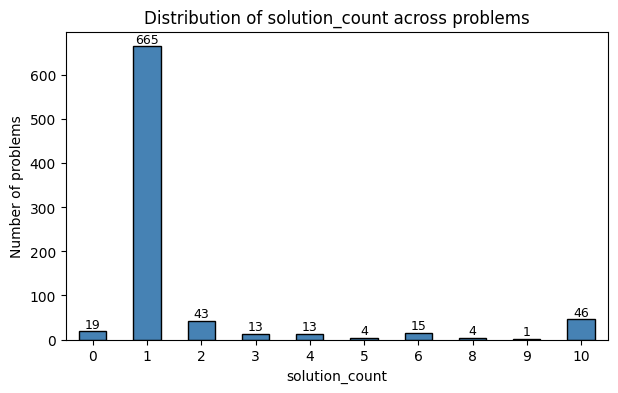

In [44]:
# Deduplicate to one row per problem id
# (solution_count and search_reached are constant within each id)
prob_df = df.drop_duplicates(subset='id')
print(f"Total rows : {len(df)}")
print(f"Unique problems (after dedup): {len(prob_df)}")

# --- solution_count distribution ---
sc = prob_df['solution_count'].value_counts(dropna=False).sort_index()
sc_pct = (sc / len(prob_df) * 100).round(2)

print("\nsolution_count distribution (per problem):")
for val, cnt in sc.items():
    print(f"  {val}: {cnt} problems ({sc_pct[val]:.2f}%)")

ax = sc.plot(kind='bar', edgecolor='black', color='steelblue', figsize=(7, 4))
ax.set_title('Distribution of solution_count across problems')
ax.set_xlabel('solution_count')
ax.set_ylabel('Number of problems')
ax.set_xticklabels(sc.index, rotation=0)
for patch, cnt in zip(ax.patches, sc.values):
    ax.text(patch.get_x() + patch.get_width() / 2, patch.get_height() + 1,
            str(cnt), ha='center', va='bottom', fontsize=9)

search_reached distribution (per problem):
  little_endian: 691 problems (83.96%)
  NaN (not reached): 94 problems (11.42%)
  digits: 38 problems (4.62%)


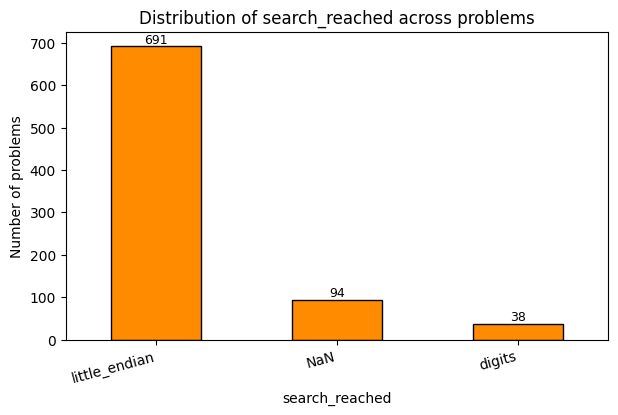

In [45]:
# --- search_reached distribution ---
sr = prob_df['search_reached'].value_counts(dropna=False)
sr_pct = (sr / len(prob_df) * 100).round(2)

print("search_reached distribution (per problem):")
for val, cnt in sr.items():
    label = str(val) if not (isinstance(val, float) and pd.isna(val)) else 'NaN (not reached)'
    print(f"  {label}: {cnt} problems ({sr_pct[val]:.2f}%)")

ax = sr.plot(kind='bar', edgecolor='black', color='darkorange', figsize=(7, 4))
ax.set_title('Distribution of search_reached across problems')
ax.set_xlabel('search_reached')
ax.set_ylabel('Number of problems')
ax.set_xticklabels(
    [str(v) if not (isinstance(v, float) and pd.isna(v)) else 'NaN' for v in sr.index],
    rotation=15, ha='right'
)
for patch, cnt in zip(ax.patches, sr.values):
    ax.text(patch.get_x() + patch.get_width() / 2, patch.get_height() + 0.5,
            str(cnt), ha='center', va='bottom', fontsize=9)